In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

In [2]:
# 도미 - 35
bream_length = [25.4, 26.3, 26.5, 29.0, 29.0, 29.7, 29.7, 30.0, 30.0, 30.7, 31.0, 31.0, 31.5, 32.0, 32.0, 32.0, 33.0, 33.0, 33.5, 33.5, 34.0, 34.0, 34.5, 35.0, 35.0, 35.0, 35.0, 36.0, 36.0, 37.0, 38.5, 38.5, 39.5, 41.0, 41.0]
bream_weight = [242.0, 290.0, 340.0, 363.0, 430.0, 450.0, 500.0, 390.0, 450.0, 500.0, 475.0, 500.0, 500.0, 340.0, 600.0, 600.0, 700.0, 700.0, 610.0, 650.0, 575.0, 685.0, 620.0, 680.0, 700.0, 725.0, 720.0, 714.0, 850.0, 1000.0, 920.0, 955.0, 925.0, 975.0, 950.0]
# 빙어 - 14
smelt_length = [9.8, 10.5, 10.6, 11.0, 11.2, 11.3, 11.8, 11.8, 12.0, 12.2, 12.4, 13.0, 14.3, 15.0]
smelt_weight = [6.7, 7.5, 7.0, 9.7, 9.8, 8.7, 10.0, 9.9, 9.8, 12.2, 13.4, 12.2, 19.7, 19.9]
length = bream_length+smelt_length
weight = bream_weight+smelt_weight

In [3]:
# 길이 29.5 무게 330 인 고기를 분류하시오.
# 길이 25, 무게 150 인 고기를 분류하시오
# 예측고기: 도미, 빙어

In [4]:
data= np.column_stack((length,weight))
label = [1]*35+[0]*14

In [5]:
data[0:2]

array([[ 25.4, 242. ],
       [ 26.3, 290. ]])

In [6]:
# 데이터 전처리
# 표준점수 고려해야 함.
# 표준점수 = (특성값 - 산술평균) / 표준편차
# axis=0은 여기서 길이 열끼리, 무게 열끼리 각각 계산
mean = np.mean(data,axis=0) # 행의 기준으로 산술평균
std = np.std(data,axis=0)   # 행의 기준으로 표준편차
train_scaled = (data-mean)/std
new_data = ([25,120]-mean)/std
new_data2 = ([29.5,300]-mean)/std

In [7]:
train_data,test_data,train_label,test_label = \
train_test_split(train_scaled,label)    # train_scaled (-1.5 - 1.5)

In [8]:
clf = KNeighborsClassifier()
clf.fit(train_data,train_label)
result = clf.predict(test_data)
score = clf.score(test_data,test_label)
print("예측 : ",score)

예측 :  1.0


In [9]:
distances,indexes = clf.kneighbors([new_data])
indexes

array([[ 4,  5, 33,  8, 14]])

In [10]:
result2 = clf.predict([new_data2])
print("예측생선 : ",result2)
# 단위를 표준점수로 맞춰줌.
result3 = clf.predict([new_data])   # 빙어로 예측이 되었으나, 표준점수를 적용후 도미로 예측됨.
print("예측생선 : ",result3)

예측생선 :  [1]
예측생선 :  [1]


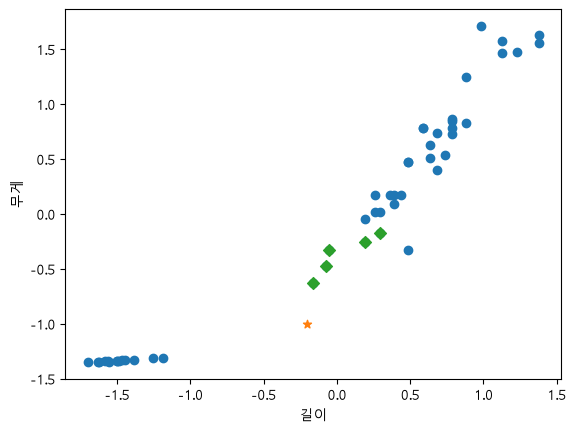

In [11]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_data[0],new_data[1],marker='*')
plt.scatter(train_data[indexes,0],train_data[indexes,1],marker='D')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

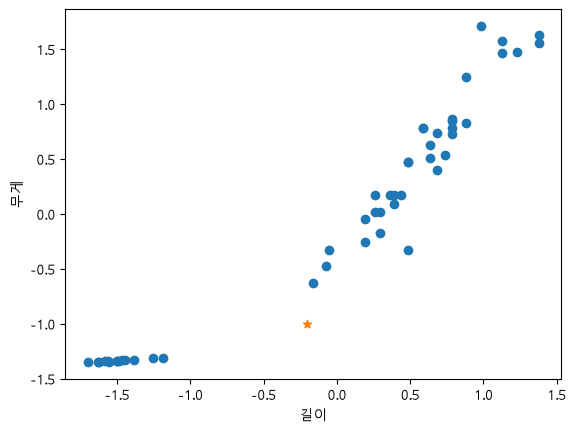

In [12]:
plt.scatter(train_scaled[:,0],train_scaled[:,1])
plt.scatter(new_data[0],new_data[1],marker='*')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()

In [13]:
train_data,test_data,train_label,test_label = \
train_test_split(data,label)

In [14]:
clf = KNeighborsClassifier()
clf.fit(train_data,train_label)
result = clf.predict(test_data)
score = clf.score(test_data,test_label)
print("예측 : ",score)

예측 :  1.0


In [15]:
result2 = clf.predict([[29.5,300]])
print("예측생선 : ",result2)
result3 = clf.predict([[25,120]])
print("예측생선 : ",result3)
distances,indexes = clf.kneighbors([[25,120]])
distances
indexes

예측생선 :  [1]
예측생선 :  [0]


array([[13, 31,  7, 26, 14]])

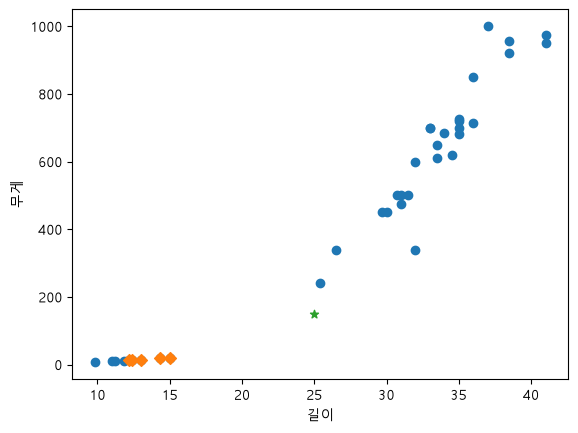

In [16]:
plt.scatter(train_data[:,0],train_data[:,1])
plt.scatter(train_data[indexes,0],train_data[indexes,1],marker='D')
# plt.scatter(29.5,300,marker='^')
plt.scatter(25,150,marker='*')
plt.xlabel('길이')
plt.ylabel('무게')
plt.show()